In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("Housing.csv")
df.head()
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished


In [3]:
df.shape

(545, 13)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [5]:
df.isnull().values.any()
df.isnull().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [6]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [7]:
4.766729-4.340000

0.4267289999999999

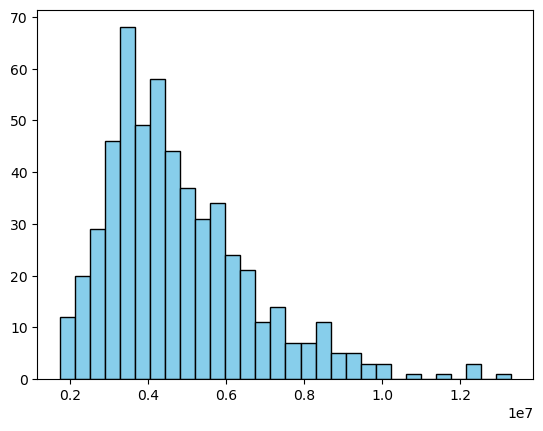

In [8]:
plt.hist(df["price"], bins=30, color="skyblue", edgecolor="black")
plt.show()

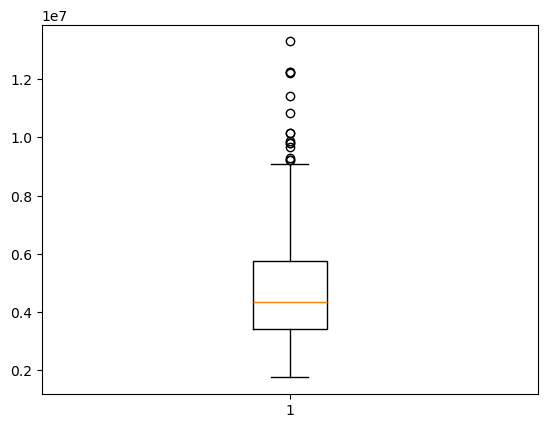

In [9]:
plt.boxplot(df["price"] )
plt.show()

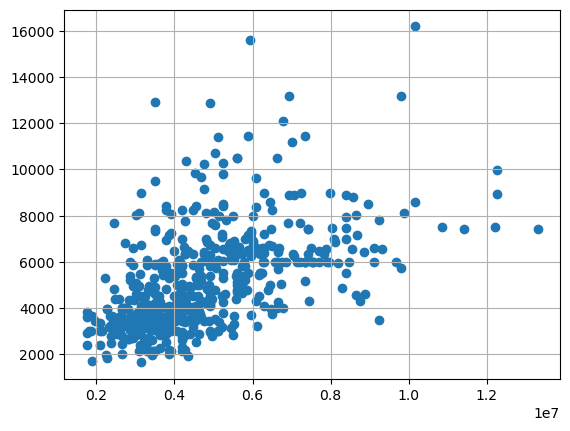

In [10]:
plt.scatter(df["price"], df["area"] )
plt.grid()
plt.show()

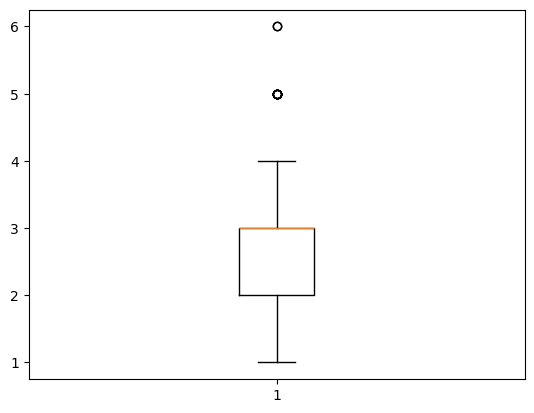

In [11]:
plt.boxplot(df["bedrooms"] )
plt.show()

C:\Users\mrsub\AppData\Local\Temp\ipykernel_2612\1120962043.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([df["price"], df["area"]], labels=["Price", "Area"])


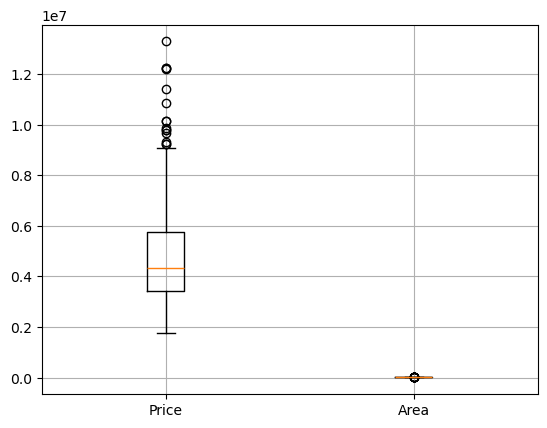

In [12]:
 

# Pass the columns as a list/subset
plt.boxplot([df["price"], df["area"]], labels=["Price", "Area"])
plt.grid(True)
plt.show()


C:\Users\mrsub\AppData\Local\Temp\ipykernel_2612\406725738.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(grouped_data, labels=categories, patch_artist=True)


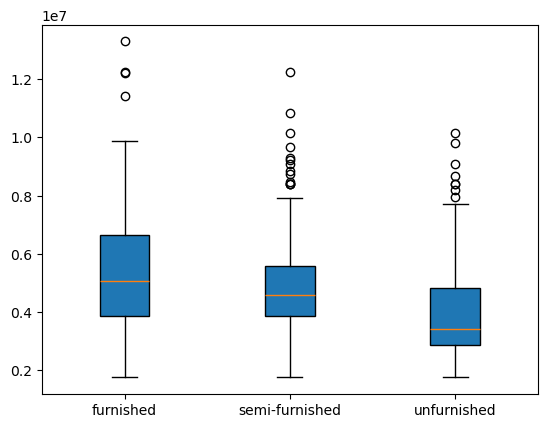

In [13]:
categories = ['furnished', 'semi-furnished', 'unfurnished']
grouped_data = [df[df['furnishingstatus'] == cat]['price'] for cat in categories]

plt.boxplot(grouped_data, labels=categories, patch_artist=True)
plt.show()

In [14]:
binary_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']

for col in binary_cols:
    df[col] = df[col].map({'yes': 1, 'no': 0})

df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,furnished
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,furnished
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,semi-furnished
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,furnished
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,1,0,1,0,0,2,0,unfurnished
541,1767150,2400,3,1,1,0,0,0,0,0,0,0,semi-furnished
542,1750000,3620,2,1,1,1,0,0,0,0,0,0,unfurnished
543,1750000,2910,3,1,1,0,0,0,0,0,0,0,furnished


In [15]:
print(df["bedrooms"].unique())

print("Types of unique values = ",df['bedrooms'].nunique()) 

print("Average bedrooms = ",df['bedrooms'].mean())

[4 3 5 2 6 1]
Types of unique values =  6
Average bedrooms =  2.9651376146788992


C:\Users\mrsub\AppData\Local\Temp\ipykernel_2612\2488848861.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(group_data, labels=Categories, patch_artist=True)


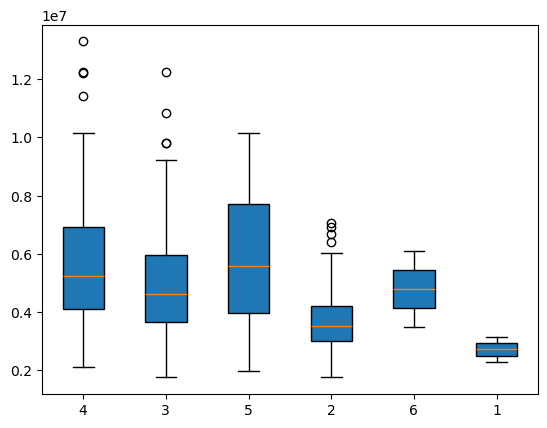

In [16]:
Categories = [4,3,5,2,6,1]
group_data = [df[df['bedrooms'] == tat]['price'] for tat in Categories]

plt.boxplot(group_data, labels=Categories, patch_artist=True)
plt.show()

In [17]:
 
print(df['bedrooms'].value_counts())


bedrooms
3    300
2    136
4     95
5     10
6      2
1      2
Name: count, dtype: int64


[2 4 1 3]
Types of unique values =  4
Average bathrooms =  1.2862385321100918
bathrooms
1    401
2    133
3     10
4      1
Name: count, dtype: int64


C:\Users\mrsub\AppData\Local\Temp\ipykernel_2612\1840537824.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groupy_data, labels=Catego, patch_artist=True)


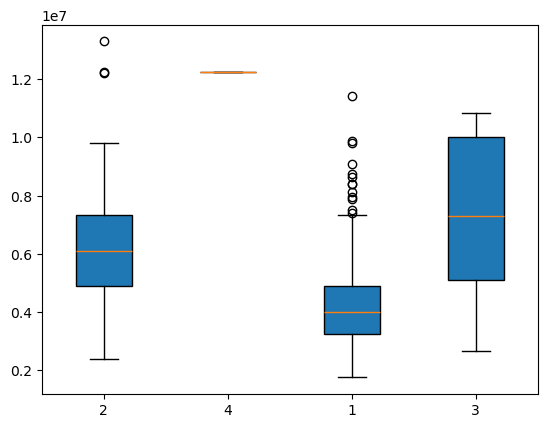

In [18]:
print(df["bathrooms"].unique())
print("Types of unique values = ",df['bathrooms'].nunique()) 
print("Average bathrooms = ",df['bathrooms'].mean())
print(df['bathrooms'].value_counts())
Catego = [2, 4, 1, 3]
groupy_data = [df[df['bathrooms'] == tac]['price'] for tac in Catego]
plt.boxplot(groupy_data, labels=Catego, patch_artist=True)
plt.show()

In [19]:
df[df['bathrooms'] == 4]

 

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,furnished


[3 4 2 1]
Types of unique values =  4
Average stories =  1.8055045871559634
stories
2    238
1    227
4     41
3     39
Name: count, dtype: int64


C:\Users\mrsub\AppData\Local\Temp\ipykernel_2612\135050359.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groupyy_data, labels=Categoo, patch_artist=True)


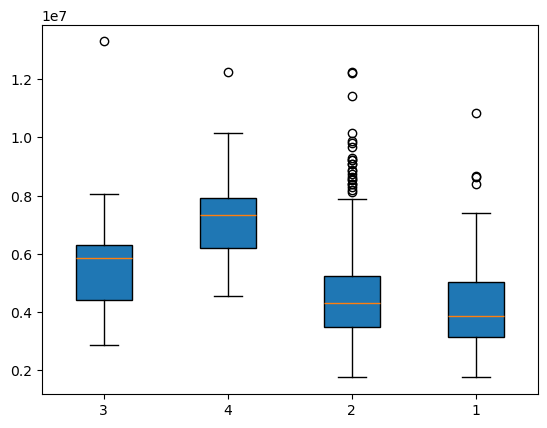

In [20]:
print(df["stories"].unique())
print("Types of unique values = ",df["stories"].nunique()) 
print("Average stories = ",df["stories"].mean())
print(df["stories"].value_counts())




Categoo = [3,4, 2, 1]
groupyy_data = [df[df["stories"] == tacc]['price'] for tacc in Categoo]
plt.boxplot(groupyy_data, labels=Categoo, patch_artist=True)
plt.show()

[2 3 0 1]
Types of unique values =  4
Average parking =  0.6935779816513762
parking
0    299
1    126
2    108
3     12
Name: count, dtype: int64


C:\Users\mrsub\AppData\Local\Temp\ipykernel_2612\2440035415.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groupx_data, labels=Categy, patch_artist=True)


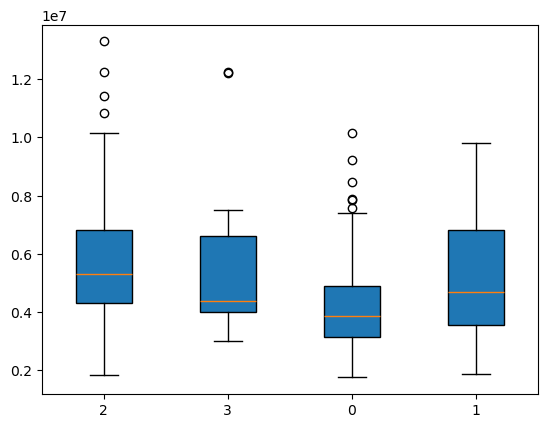

In [21]:
print(df["parking"].unique())
print("Types of unique values = ",df["parking"].nunique()) 
print("Average parking = ",df["parking"].mean())
print(df["parking"].value_counts())




Categy = [2,3, 0, 1]
groupx_data = [df[df["parking"] == tacx]['price'] for tacx in Categy]
plt.boxplot(groupx_data, labels=Categy, patch_artist=True)
plt.show()

C:\Users\mrsub\AppData\Local\Temp\ipykernel_2612\2296476558.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_to_plot, labels=labels )


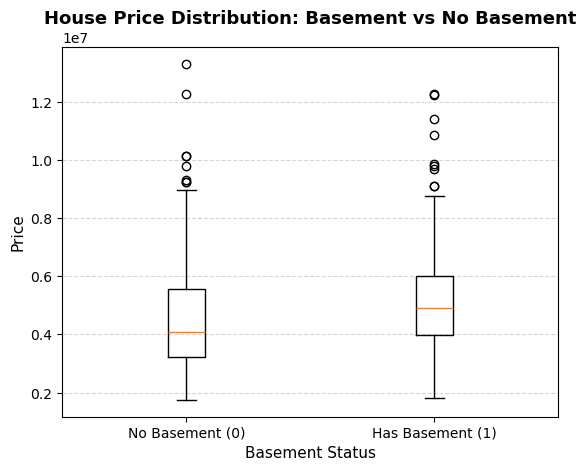

basement
0    354
1    191
Name: count, dtype: int64


In [22]:
prices_0 = df[df['basement'] == 0]['price']
prices_1 = df[df['basement'] == 1]['price']

 
data_to_plot = [prices_0, prices_1]
labels = ['No Basement (0)', 'Has Basement (1)']

 

plt.boxplot(data_to_plot, labels=labels )

plt.title('House Price Distribution: Basement vs No Basement', fontsize=13, fontweight='bold')

plt.xlabel('Basement Status', fontsize=11)
plt.ylabel('Price', fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.5)


plt.show()

print(df["basement"].value_counts())


In [23]:
print(df["basement"].value_counts())

basement
0    354
1    191
Name: count, dtype: int64


C:\Users\mrsub\AppData\Local\Temp\ipykernel_2612\1038326221.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_to_plot, labels=labels)


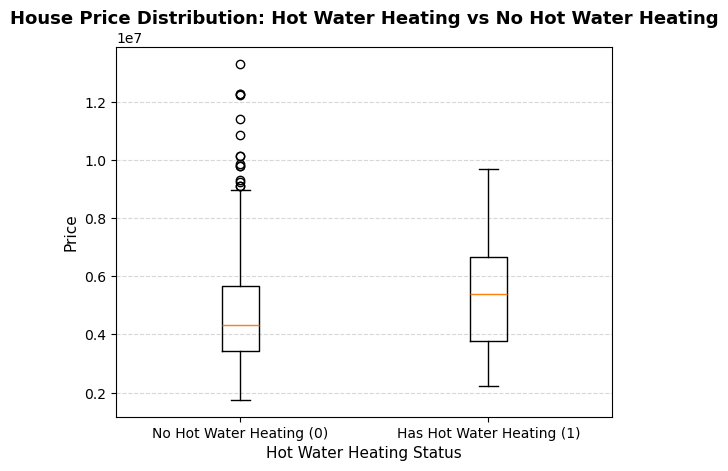

hotwaterheating
0    520
1     25
Name: count, dtype: int64


In [24]:
 

# 1. Filter the price column directly by the numeric 0 and 1 values for hotwaterheating
prices_0 = df[df['hotwaterheating'] == 0]['price']
prices_1 = df[df['hotwaterheating'] == 1]['price']

# 2. Package the groups together with matching labels
data_to_plot = [prices_0, prices_1]
labels = ['No Hot Water Heating (0)', 'Has Hot Water Heating (1)']

# 3. Render the plot natively
plt.boxplot(data_to_plot, labels=labels)

# 4. Add your exact titles and labels
plt.title('House Price Distribution: Hot Water Heating vs No Hot Water Heating', fontsize=13, fontweight='bold')
plt.xlabel('Hot Water Heating Status', fontsize=11)
plt.ylabel('Price', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

# 5. Print the raw category row counts
print(df["hotwaterheating"].value_counts())


C:\Users\mrsub\AppData\Local\Temp\ipykernel_2612\1546064833.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_to_plot, labels=labels)


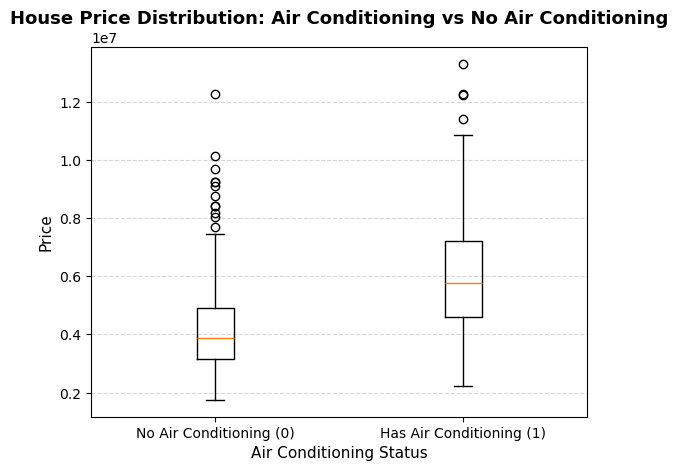

airconditioning
0    373
1    172
Name: count, dtype: int64


In [25]:
# 1. Filter the price column directly by the numeric 0 and 1 values for airconditioning
prices_0 = df[df['airconditioning'] == 0]['price']
prices_1 = df[df['airconditioning'] == 1]['price']

# 2. Package the groups together with matching labels
data_to_plot = [prices_0, prices_1]
labels = ['No Air Conditioning (0)', 'Has Air Conditioning (1)']

# 3. Render the plot natively
plt.boxplot(data_to_plot, labels=labels)

# 4. Add your exact titles and labels
plt.title('House Price Distribution: Air Conditioning vs No Air Conditioning', fontsize=13, fontweight='bold')
plt.xlabel('Air Conditioning Status', fontsize=11)
plt.ylabel('Price', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

# 5. Print the raw category row counts
print(df["airconditioning"].value_counts())


C:\Users\mrsub\AppData\Local\Temp\ipykernel_2612\1345014497.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_to_plot, labels=labels)


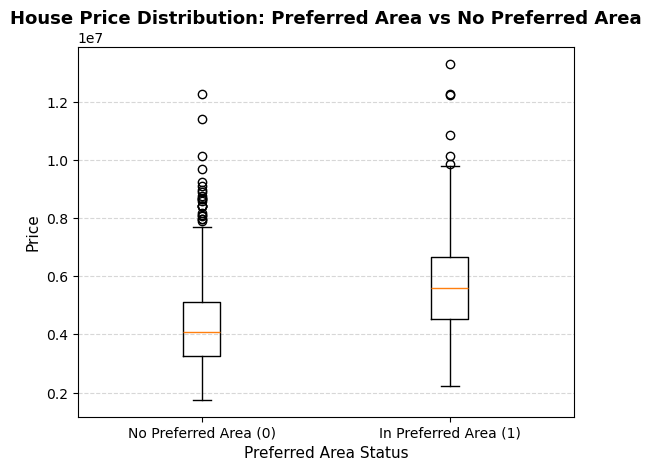

prefarea
0    417
1    128
Name: count, dtype: int64


In [26]:
# 1. Filter the price column directly by the numeric 0 and 1 values for prefarea
prices_0 = df[df['prefarea'] == 0]['price']
prices_1 = df[df['prefarea'] == 1]['price']

# 2. Package the groups together with matching labels
data_to_plot = [prices_0, prices_1]
labels = ['No Preferred Area (0)', 'In Preferred Area (1)']

# 3. Render the plot natively
plt.boxplot(data_to_plot, labels=labels)

# 4. Add your exact titles and labels
plt.title('House Price Distribution: Preferred Area vs No Preferred Area', fontsize=13, fontweight='bold')
plt.xlabel('Preferred Area Status', fontsize=11)
plt.ylabel('Price', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

# 5. Print the raw category row counts
print(df["prefarea"].value_counts())


C:\Users\mrsub\AppData\Local\Temp\ipykernel_2612\32517065.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_mainroad, labels=labels_mainroad)


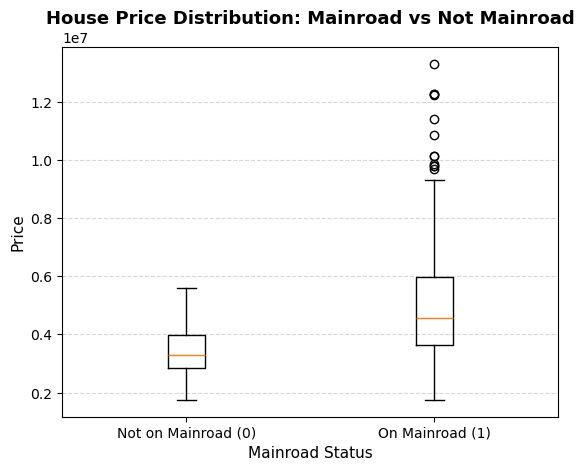

--- MAINROAD COUNTS ---
mainroad
1    468
0     77
Name: count, dtype: int64




C:\Users\mrsub\AppData\Local\Temp\ipykernel_2612\32517065.py:34: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_guestroom, labels=labels_guestroom)


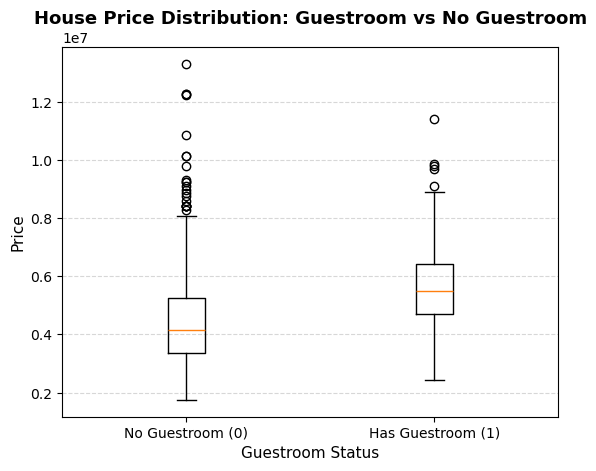

--- GUESTROOM COUNTS ---
guestroom
0    448
1     97
Name: count, dtype: int64


In [27]:
# --- 1. MAINROAD PLOT ---
# Filter data
prices_mainroad_0 = df[df['mainroad'] == 0]['price']
prices_mainroad_1 = df[df['mainroad'] == 1]['price']

# Setup plot layout
data_mainroad = [prices_mainroad_0, prices_mainroad_1]
labels_mainroad = ['Not on Mainroad (0)', 'On Mainroad (1)']

# Render Mainroad Plot
plt.boxplot(data_mainroad, labels=labels_mainroad)
plt.title('House Price Distribution: Mainroad vs Not Mainroad', fontsize=13, fontweight='bold')
plt.xlabel('Mainroad Status', fontsize=11)
plt.ylabel('Price', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# Print counts
print("--- MAINROAD COUNTS ---")
print(df["mainroad"].value_counts())
print("\n" + "="*40 + "\n")


# --- 2. GUESTROOM PLOT ---
# Filter data
prices_guestroom_0 = df[df['guestroom'] == 0]['price']
prices_guestroom_1 = df[df['guestroom'] == 1]['price']

# Setup plot layout
data_guestroom = [prices_guestroom_0, prices_guestroom_1]
labels_guestroom = ['No Guestroom (0)', 'Has Guestroom (1)']

# Render Guestroom Plot
plt.boxplot(data_guestroom, labels=labels_guestroom)
plt.title('House Price Distribution: Guestroom vs No Guestroom', fontsize=13, fontweight='bold')
plt.xlabel('Guestroom Status', fontsize=11)
plt.ylabel('Price', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# Print counts
print("--- GUESTROOM COUNTS ---")
print(df["guestroom"].value_counts())


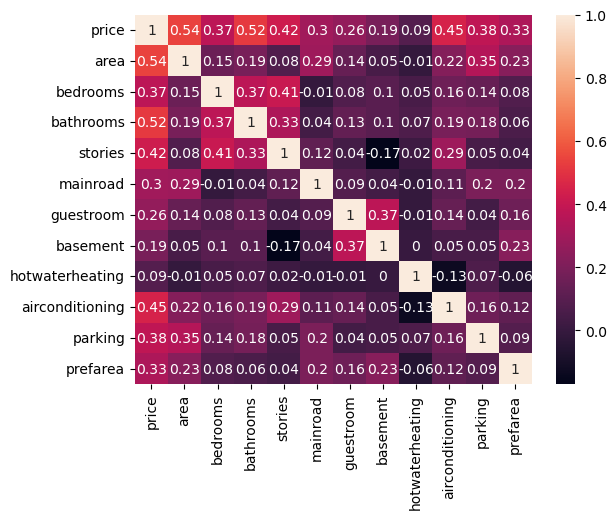

price              1.00
area               0.54
bathrooms          0.52
airconditioning    0.45
stories            0.42
parking            0.38
bedrooms           0.37
prefarea           0.33
mainroad           0.30
guestroom          0.26
basement           0.19
hotwaterheating    0.09
Name: price, dtype: float64


In [76]:
import seaborn as sns

my_matrix = df.drop(columns=['furnishingstatus']).corr().round(2)

sns.heatmap(my_matrix, annot = True)
plt.show()

price_corr = my_matrix['price']
sorting = price_corr.sort_values(ascending=False)
print(sorting)

In [78]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X = df[['area']]   
y = df['price'] 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model_a = LinearRegression()

model_a.fit(X_train, y_train)

y_pred_a = model_a.predict(X_test)

comparison = pd.DataFrame({'Actual Price': y_test,'Predicted Price': y_pred_a})

print(comparison.head(10))

     Actual Price  Predicted Price
316       4060000     5.024060e+06
77        6650000     5.279498e+06
360       3710000     4.232203e+06
90        6440000     4.640903e+06
493       2800000     4.198144e+06
209       4900000     5.373159e+06
176       5250000     6.139473e+06
249       4543000     4.636646e+06
516       2450000     3.891619e+06
426       3353000     3.661725e+06


In [80]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred_a)

rmse = mean_squared_error(y_test, y_pred_a) ** 0.5
 
r2 = r2_score(y_test, y_pred_a)
 
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 1474748.1337969352
RMSE: 1917103.7021424233
R2 Score: 0.27287851871974644


In [100]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

X = df.drop(columns=['price'])
y = df['price']

preprocessor = ColumnTransformer(
    transformers=[('furnishing', OneHotEncoder(drop='first', handle_unknown='ignore'),      ['furnishingstatus'])],      remainder='passthrough')


X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X, y, test_size=0.2,random_state=42)

model_b = Pipeline([('preprocessor', preprocessor),('regressor', LinearRegression())])

model_b.fit(X_train_b, y_train_b)

y_pred_b = model_b.predict(X_test_b)

comparison_b = pd.DataFrame({
    'Actual Price': y_test_b,
    'Predicted Price': y_pred_b })

print(comparison_b.head(10))

     Actual Price  Predicted Price
316       4060000     5.164654e+06
77        6650000     7.224722e+06
360       3710000     3.109863e+06
90        6440000     4.612075e+06
493       2800000     3.294646e+06
209       4900000     3.532275e+06
176       5250000     5.611775e+06
249       4543000     6.368146e+06
516       2450000     2.722857e+06
426       3353000     2.629406e+06


In [102]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test_b,  y_pred_b)

rmse = mean_squared_error(y_test_b,  y_pred_b) ** 0.5
 
r2 = r2_score(y_test_b,  y_pred_b)
 
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 970043.4039201728
RMSE: 1324506.9600914817
R2 Score: 0.6529242642152959


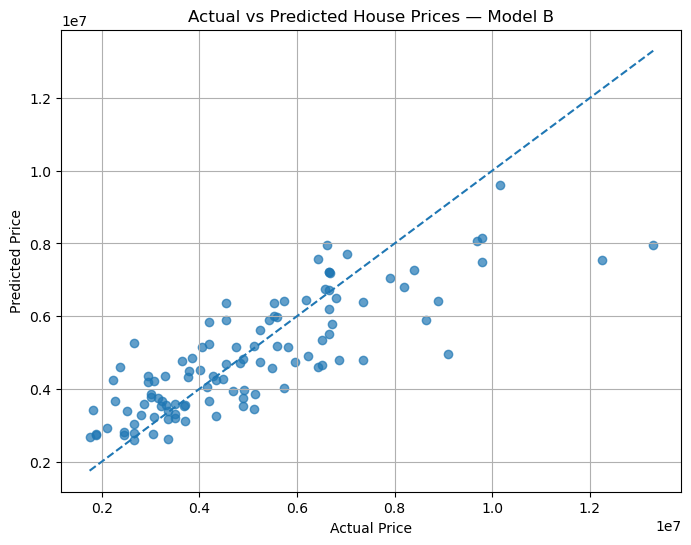

In [104]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test_b, y_pred_b, alpha=0.7)

# Reference line representing perfect predictions
minimum = min(y_test_b.min(), y_pred_b.min())
maximum = max(y_test_b.max(), y_pred_b.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle='--'
)

plt.title('Actual vs Predicted House Prices — Model B')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')

plt.grid(True)
plt.show()

In [106]:
residuals = y_test_b.values - y_pred_b

residual_data = pd.DataFrame({
    'Actual Price': y_test_b.values,
    'Predicted Price': y_pred_b,
    'Residuals': residuals
})

print(residual_data.head(10))

   Actual Price  Predicted Price     Residuals
0       4060000     5.164654e+06 -1.104654e+06
1       6650000     7.224722e+06 -5.747223e+05
2       3710000     3.109863e+06  6.001368e+05
3       6440000     4.612075e+06  1.827925e+06
4       2800000     3.294646e+06 -4.946463e+05
5       4900000     3.532275e+06  1.367725e+06
6       5250000     5.611775e+06 -3.617746e+05
7       4543000     6.368146e+06 -1.825146e+06
8       2450000     2.722857e+06 -2.728570e+05
9       3353000     2.629406e+06  7.235944e+05


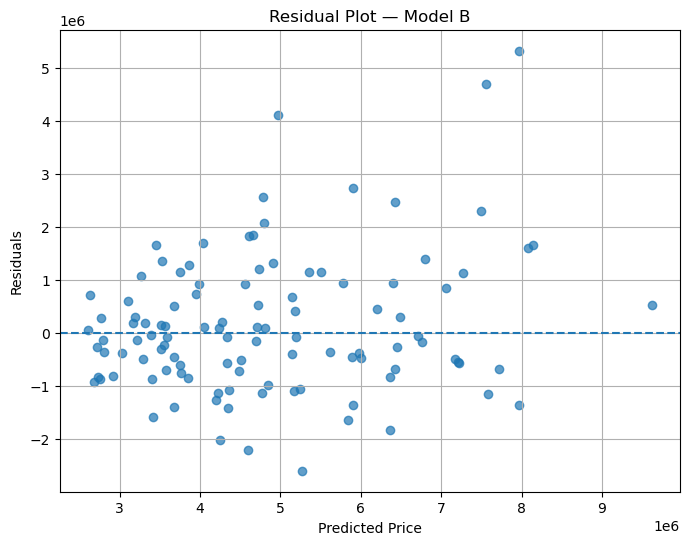

In [108]:
plt.figure(figsize=(8, 6))

plt.scatter(y_pred_b, residuals, alpha=0.7)

plt.axhline(y=0, linestyle='--')

plt.title('Residual Plot — Model B')
plt.xlabel('Predicted Price')
plt.ylabel('Residuals')

plt.grid(True)
plt.show()